# Graph Models - (MLX)

The following demos using MolMiner-Graphs. Currently, the package comes with four GNN algorithms - a general Graph Convolutional Neural Network (GNNNet), a Graph Isomorphism with Edge Features (GINENet), GraphSAGE (GSAGENet), and Graph Attention Network (GATNet). Additional Graph algorithms may be considered in the future.

The graph neural networks are called as a Class and share similar parameters. Of the networks, only the GINENet will utilize the edge_attr (i.e. bond types) as features when training the model by default. Otherwise, both Classes should be able to be able to be initialized and fit according to this tutorial. Only pertinent parameters are shown and each Class contains additional parameters not shown here. Users are encouraged to dig into the documentation to explore further.

**NOTE:** This package is built using [MLX](https://github.com/ml-explore/mlx) and [MLX-graphs](https://github.com/mlx-graphs/mlx-graphs). The classes and parameters are similar to those found with the PyTorch version.

 ## Import Modules

Unlike the PyTorch version, the MLX code will utilize the Apple Silicon GPU by default. No explicit stating of GPU or CPU is needed unless specifically specified.

In [1]:
import pandas as pd
from tqdm import tqdm
import numpy as np
import random
import mlx.core as mx
from mlx_graphs.loaders import Dataloader
from mminer_graphs.mlx_models import MolToGraph, GCNNet, GINENet, GSAGENet, GATNet, EarlyStopping, summary
from mminer_graphs.plot.mlx_plot import PlotsMLX

Optional: Setting the seed to ensure reproducibility.

In [2]:
random.seed(451)
np.random.seed(451)
mx.random.seed(451)

# Classification

## Dataset Prep
The sample dataset is taken from [MoleculeNet](https://moleculenet.org) and uses their BACE dataset. This dataset includes quantitative (IC50) and qualitative (binary labels) binding results for inhibitors of human beta secretase (BACE-1). The only modification to the dataset was replacing their default split with a random split and including cross-validation columns with random splits.

In this case, a model will be created using a single split (Model). After extracting the necessary information, the Data will contain the following format:

In [3]:
data = pd.read_csv("../dataset/bace.csv")
cols = ['CID', 'smiles', 'Class', 'Model']
dataset = data[cols]
print(f"The shape of the dataset: {dataset.shape}")
dataset.head()

The shape of the dataset: (1513, 4)


,CID,smiles,Class,Model
0,BACE_1,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,1,train
1,BACE_2,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,1,train
2,BACE_3,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train
3,BACE_4,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,1,train
4,BACE_5,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train


### Convert to Graph Data

The dataset will need to be converted into graphs. Here, the data will be split into the train and test set (or also a validation set, but this is not used here). Using the MolToGraph() method, the molecules will be converted into graphs. By default, the AtomGraph will be used. The graphs will be loaded into a list.

In [4]:
train = dataset[dataset.iloc[:, -1] == 'train']
test = dataset[dataset.iloc[:, -1] == 'test']

train_list = [MolToGraph(smi=smi, label=y).graph_data for smi, y in tqdm(zip(train.smiles, train.Class), desc="Converting Train Graphs")]
test_list = [MolToGraph(smi=smi, label=y).graph_data for smi, y in tqdm(zip(test.smiles, test.Class), desc="Converting Test Graphs")]

Converting Train Graphs: 1376it [00:02, 618.53it/s]
Converting Test Graphs: 137it [00:00, 617.55it/s]


This will generate a list containing mlx-graph Data objects with four MLX arrays. The shapes of the arrays are:
* **x** = [num_nodes, num_features]
* **edge_index** = [2, num_edge_features]
* **edge_attr** = [num_edges, num_edge_features]
* **y** = [class_label]

In [5]:
train_list[:1]

[GraphData(
 	edge_index(shape=(2, 70), int32)
 	node_features(shape=(32, 142), float32)
 	edge_features(shape=(70, 16), float32)
 	y(shape=(1,), float32))]

*Optional*

The model requires the data to be in a list or as a MLX class Dataloader. If a list is given, then the list will be converted into the MLX class Dataloader internally (so this section can technically be deleted). In this part of the tutorial, the list will be converted into a MLX Dataloader class (below).

In [6]:
# load data
train_loader = Dataloader(train_list, batch_size=1024, shuffle=True)  # shuffle to avoid overfitting to sample order
test_loader = Dataloader(test_list, batch_size=1024)

print(f"Training Data: {len(train_loader.dataset)}")
print(f"Test Data: {len(test_loader.dataset)}")

Training Data: 1376
Test Data: 137


The graph information set as a Dataloader can be visualized using .dataset. This will generate a list of the graph data. Only the first 5 are printed to save space.

In [7]:
train_loader.dataset[:5]

[GraphData(
 	edge_index(shape=(2, 70), int32)
 	node_features(shape=(32, 142), float32)
 	edge_features(shape=(70, 16), float32)
 	y(shape=(1,), float32)),
 GraphData(
 	edge_index(shape=(2, 100), int32)
 	node_features(shape=(47, 142), float32)
 	edge_features(shape=(100, 16), float32)
 	y(shape=(1,), float32)),
 GraphData(
 	edge_index(shape=(2, 92), int32)
 	node_features(shape=(42, 142), float32)
 	edge_features(shape=(92, 16), float32)
 	y(shape=(1,), float32)),
 GraphData(
 	edge_index(shape=(2, 84), int32)
 	node_features(shape=(40, 142), float32)
 	edge_features(shape=(84, 16), float32)
 	y(shape=(1,), float32)),
 GraphData(
 	edge_index(shape=(2, 96), int32)
 	node_features(shape=(44, 142), float32)
 	edge_features(shape=(96, 16), float32)
 	y(shape=(1,), float32))]

## Training the Model

To train the model, the network class must first be instantiated. There are several parameters needed to ensure that the model runs without issue. By default, the parameters will be set to utilize the AtomGraph, but can be changed to encompass different molecular graph data. For clarity, the necessary information will be given where applicable.

In this example, the GCNNet is called. The node dimensions corresponds to the input features for the graph. For AtomGraph, that is 142. The hidden_dim sets graph feature vector output for the layer. If the parameter ***reduce_graph*** is set to True, then the graph feature vector will be halved in each subsequent graph layer. In this example, each graph layer feature vector will be set to 128. The ***graph_layers*** parameter will set the number of graph layers. The output feature vectors will match the hidden_dim and reduce_graph parameters settings. The final graph latent vector will be generated and fed into the MLP layers.

Next, the ***mlp_layers*** parameter will set the number of layers to use in the MLP section of the model. By default, the number of nodes in the first MLP layer will be set to the output of the graph latent vector. This will be halved for each subsequent layer. A dropout can be initiated in the MLP layers. In this example, the graph_dropout and mlp_dropout is set to 0.

Finally, the class includes a ***num_classes*** parameter. This will set the number of classes in the final output layer. For classification this is set to 2.

**NOTE:** The code has not been tested for multi-label models.

In [8]:
model = GCNNet(node_dim=142, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, num_classes=2)

The GCNNet class above was set to the variable **model**. This can be printed to check on the created model. This will print out the model, its graph, and its MLP layers.

A summary in tabular format can also be printed by using the **summary()** method. This requires the instantiated model and the dataset used for training/testing.

In [9]:
print(summary(model))

GCNNet                                             Shape                              Params
└─(gcn_conv)                                       --                                 51,328
    ├─(0)                                          --                                 18,304
    │   └─(linear)                                 --                                 18,304
    │       ├─(weight)                             (128, 142)                         18,176
    │       └─(bias)                               (128,)                                128
    ├─(1)                                          --                                 16,512
    │   └─(linear)                                 --                                 16,512
    │       ├─(weight)                             (128, 128)                         16,384
    │       └─(bias)                               (128,)                                128
    └─(2)                                          --                 

**EarlyStopping** can also be set. Here it will be called to monitor the validation/test data.

In this tutorial, the **EarlyStopping** class is instantiated, but the patience is set at 75.

In [10]:
estop = EarlyStopping(monitor='val_loss', patience=75, mode='min')

The model can be fit in a similar fashion to the sklearn api by calling the **.fit()** instance method. There are several mandatory parameters needed to ensure that the model is fitted:
- The training dataset
- The test dataset

Additional parameters include setting the epochs number, the optimizer, and using early stopping (estop). A special parameter, **device** will determine where the MLX arrays are to be trained. By default, this is set to "auto" and will utilize the Apple Silicon gpu.

In [11]:
model.fit(train_loader, test_loader, epochs=100, optimizer="adam", device='auto', estop=estop)

Model running on Apple M2 Pro


Epoch: 100%|██████████| 100/100 [00:17<00:00,  5.84it/s]

Best Training Loss: 0.187
Best Test Loss: 0.415
Best Training Accuracy: 0.915
Best Test Accuracy: 0.803


## Plots

The mol-miner-graphs comes with basic plot functions. This section will demo their usage.

### Curves
The **curves()** method will generate the loss curve and accuracy curves for the model. It will use the results from the Test data. The figure here is drawn with default settings, however the **curves()** method contains additional parameters, such as line colors, figsize, or other metrics to plot (Precision).

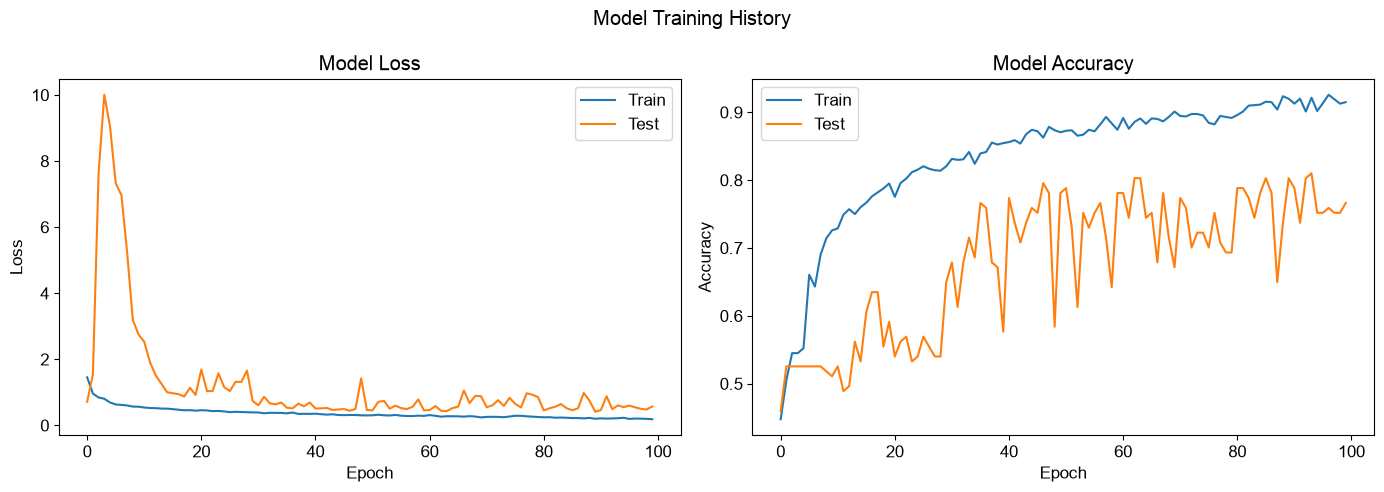

In [12]:
plot = PlotsMLX(model, data_loader=test_loader)
plot.curves()

### Confusion Matrix

A confusion matrix can be drawn using the **confusion_matrix()** method. The class names will default to 0 and 1. Here, they are renamed as "Inactive" and "Active" using the **class_names** parameter. The device is an important parameter and should be modified to be the same input as what was used in the **.fit()** instance variable. For example, if the model was fitted using 'cpu', then the confusion matrix device should be set to 'cpu'. Additional parameters are available to modify the title, figsize, and cmap.

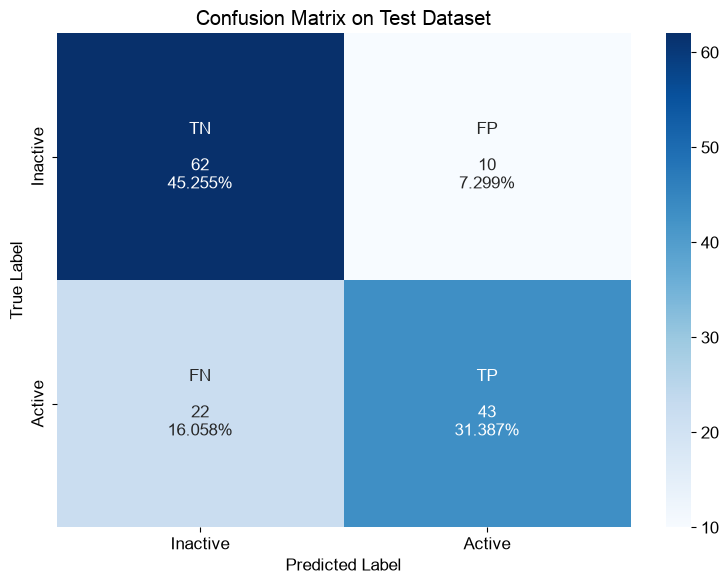

In [13]:
plot.confusion_matrix(class_names=['Inactive', 'Active'])

### Classification Report
A classification report can also be generated. The parameters are similar to the **confusion_matrix()** method.

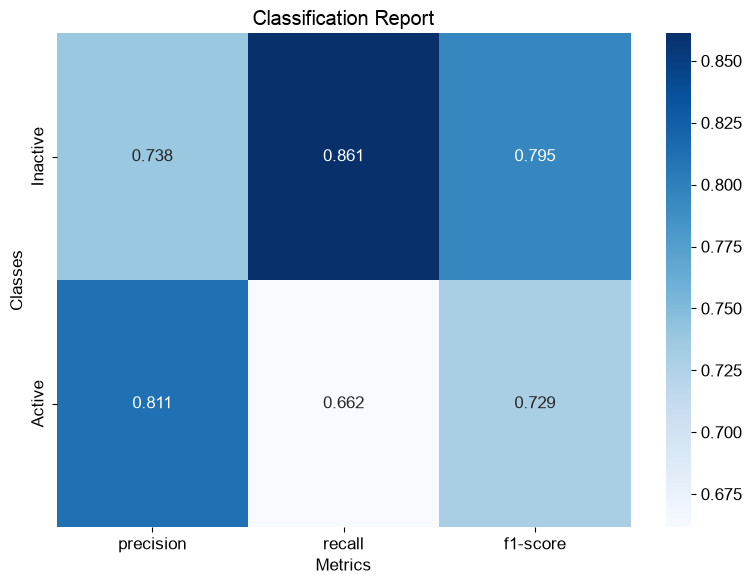

In [14]:
plot.classification_report(class_names=['Inactive', 'Active'])

An **[roc_curve()](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html)** can be drawn and displays the classifier output quality.

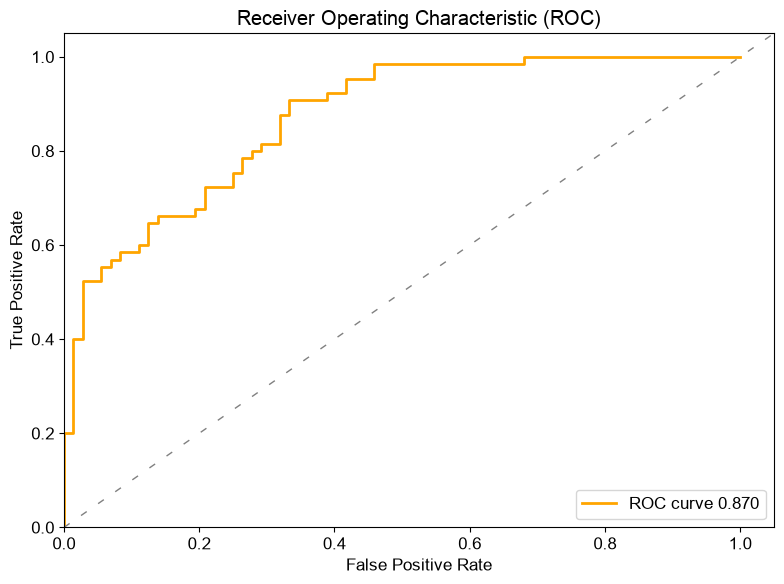

In [15]:
plot.roc_curve(model=model)

The **[pr_curve()](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)** can be drawn to show the tradeoff between precision and recall for different thresholds.

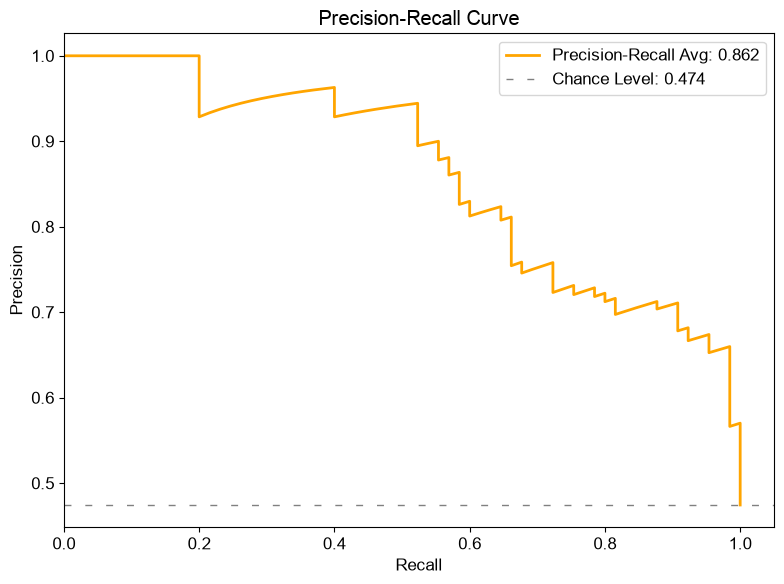

In [16]:
plot.pr_curve(model=model, chance_level=True)

## Making Predictions

Additionally, the mol-miner-graphs package contains a **.predict()** for making predictions with a trained model. This will output as a list, ndarray, or tensor. By default, the **.predict()** method  it will output results as a list for easier use with pd.DataFrames. In this example, the results are given as a MLX array.

In [17]:
pred = model.predict(test_loader, batch_size=1024, binary=True, return_type="array")
pred

array([1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0], dtype=int32)

## Saving and Loading a Model
After fitting a model, they can be saved and loaded using the **.save()** or **.load()** instance variables. For MLX models, the saved model must have the *.npz* extension.

In [18]:
model.save("test.npz")

To load a molecule, a model must be initialized using the same param as was used for saved model. For this example, teh same GCNNet used above was pasted to reset the model variable.

In [19]:
model = GCNNet(node_dim=142, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, num_classes=2)
print(f"Is the model fitted? {model.is_fitted}")

Is the model fitted? False


The saved model is then loaded using the **.load()** instance variable. Note that the device for loading the model also uses CPU. A summary of the model can be seen below.

In [20]:
model.load("test.npz")
print(f"Is the model fitted? {model.is_fitted}")
print(f"\n\n{summary(model)}")

Model loaded!
Is the model fitted? True


GCNNet                                             Shape                              Params
└─(gcn_conv)                                       --                                 51,328
    ├─(0)                                          --                                 18,304
    │   └─(linear)                                 --                                 18,304
    │       ├─(weight)                             (128, 142)                         18,176
    │       └─(bias)                               (128,)                                128
    ├─(1)                                          --                                 16,512
    │   └─(linear)                                 --                                 16,512
    │       ├─(weight)                             (128, 128)                         16,384
    │       └─(bias)                               (128,)                                128
    └─(2)                   

# Regression

Regression models are built similarly to Classification models demoed above. The main parameter changes are with the criterion and the num_classes.

## Dataset Prep
The dataset for this example will use the same as above, with the dataset taken form [MoleculeNet](https://moleculenet.org) and uses their BACE dataset. Instead of qualitative binding (binary labels) , the demo will utilize the quantitative (pIC50) labels for inhibitors of human beta secretase (BACE-1).

The dataset will be prepared as follows:

In [21]:
cols = ['CID', 'smiles', 'pIC50', 'Model']
dataset = data[cols]
print(f"The shape of the dataset: {dataset.shape}")
dataset.head()

The shape of the dataset: (1513, 4)


,CID,smiles,pIC50,Model
0,BACE_1,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,9.154901,train
1,BACE_2,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,8.853872,train
2,BACE_3,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,8.698970,train
3,BACE_4,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,8.698970,train
4,BACE_5,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,8.698970,train


Unlike the data input in the Classification demo, this data will input a list containing the graph data instead. Note that both a list of graph data or a MLX-graph Dataloader class is acceptable.

In [22]:
train = dataset[dataset.iloc[:, -1] == 'train']
test = dataset[dataset.iloc[:, -1] == 'test']

train_list = [MolToGraph(smi=smi, label=y).graph_data for smi, y in tqdm(zip(train.smiles, train.pIC50), desc="Converting Train Graphs")]
test_list = [MolToGraph(smi=smi, label=y).graph_data for smi, y in tqdm(zip(test.smiles, test.pIC50), desc="Converting Test Graphs")]
train_list[:1]

Converting Train Graphs: 1376it [00:02, 590.71it/s]
Converting Test Graphs: 137it [00:00, 567.44it/s]


[GraphData(
 	edge_index(shape=(2, 70), int32)
 	node_features(shape=(32, 142), float32)
 	edge_features(shape=(70, 16), float32)
 	y(shape=(1,), float32))]

## Training the Model
Training the model will work similarly to the Classification model above. For this example, a GINE model will be created instead. Note that for Regression models, the num_classes is set to 1.

In [23]:
model = GINENet(node_dim=142, edge_feat_dim=16, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, graph_dropout= 0, mlp_dropout=0, num_classes=1)

In [24]:
print(summary(model))

GINENet                                            Shape                              Params
└─(gine_conv)                                      --                                109,166
    ├─(0)                                          --                                 37,742
    │   ├─(mlp)                                    --                                 35,328
    │   │   └─(layers)                             --                                 35,328
    │   │       ├─(0)                              --                                 18,304
    │   │       │   ├─(weight)                     (128, 142)                         18,176
    │   │       │   └─(bias)                       (128,)                                128
    │   │       ├─(1)                              --                                    512
    │   │       │   ├─(weight)                     (128,)                                128
    │   │       │   ├─(bias)                       (128,)             

### Fitting the Model

For regression models, the criterion will need to be changed. All other parameters should be similar to what was used for Classification models.

In [25]:
model.fit(train_list, test_list, epochs=100, batch_size=1024, optimizer="adam", estop=estop, criterion="mse")

Model running on Apple M2 Pro


Epoch: 100%|██████████| 100/100 [00:18<00:00,  5.34it/s]

Best Training Loss: 0.097
Best Test Loss: 0.297
Best Training MAE: 0.327
Best Test MAE: 0.572


## Plot

### Curves
The **curves()** method will generate the loss curve and the associated Regression metric. What is plotted can be given as a list.

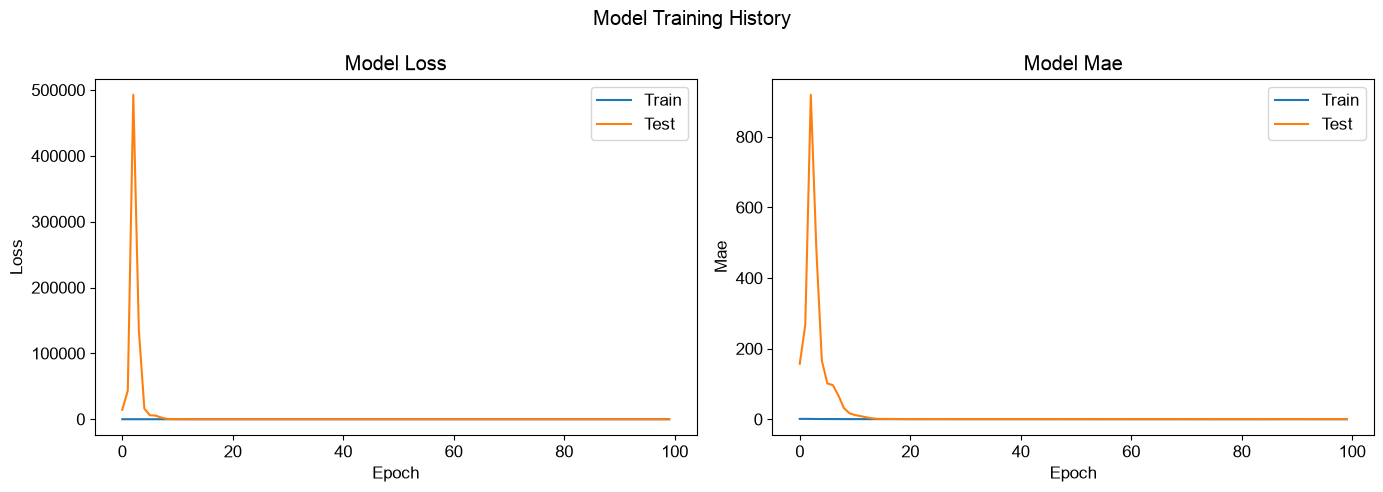

In [26]:
plot = PlotsMLX(model, data_loader=test_list)
plot.curves(metrics=['loss', 'mae'])

For Regression models, a regression plot can be drawn.

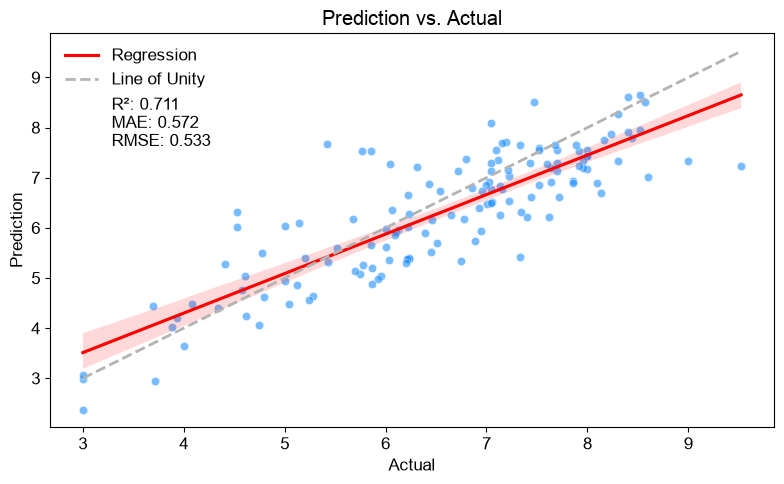

In [27]:
plot.regression()

## Additional Graph Algorithms
The mol-miner-graphs contains two additional graph neural network algorithms. They share similar parameters as seen with the models called above in the tutorial. Here, an example is show for Graph Attention Network (GATNet) and GraphSAGE network (GSAGENet).

In [28]:
model = GATNet(node_dim=142, edge_feat_dim=16, hidden_dim=128, graph_layers=2, mlp_layers=2, mlp_dropout=0, num_classes=2, heads=1,
               reduce_graph=False)

print(summary(model))

GATNet                                             Shape                              Params
└─(gat_conv)                                       --                                 39,680
    ├─(0)                                          --                                 20,736
    │   ├─(lin_proj)                               --                                 18,176
    │   │   └─(weight)                             (128, 142)                         18,176
    │   ├─(att_src)                                (1, 1, 128)                           128
    │   ├─(att_dst)                                (1, 1, 128)                           128
    │   ├─(bias)                                   (128,)                                128
    │   ├─(edge_lin_proj)                          --                                  2,048
    │   │   └─(weight)                             (128, 16)                           2,048
    │   └─(edge_att)                               (1, 1, 128)        

In [29]:
model = GSAGENet(node_dim=142, hidden_dim=128, graph_layers=2, mlp_layers=2, mlp_dropout=0, num_classes=2, reduce_graph=False)

print(summary(model))

GSAGENet                                           Shape                              Params
└─(sage_conv)                                      --                                 69,376
    ├─(0)                                          --                                 36,480
    │   ├─(neigh_proj)                             --                                 18,176
    │   │   └─(weight)                             (128, 142)                         18,176
    │   └─(self_proj)                              --                                 18,304
    │       ├─(weight)                             (128, 142)                         18,176
    │       └─(bias)                               (128,)                                128
    └─(1)                                          --                                 32,896
        ├─(neigh_proj)                             --                                 16,384
        │   └─(weight)                             (128, 128)         